In [1]:
import sqlite3
import pandas as pd
con = sqlite3.connect("customers.db")

con.execute("DROP TABLE IF EXISTS customers")
con.execute("""
CREATE TABLE customers (
    id INTEGER PRIMARY KEY,
    name TEXT,
    city TEXT,
    age INTEGER)
""")

In [2]:
con.execute("INSERT INTO customers VALUES (1, 'Jack', 'Los Angeles', 21)")
con.execute("INSERT INTO customers VALUES (2, 'Jill', 'Santa Monica', 35)")
con.execute("INSERT INTO customers VALUES (3, 'Jason', 'Culver City', 29)")
con.execute("INSERT INTO customers VALUES (4, 'James', 'Torrance', 43)")
con.execute("INSERT INTO customers VALUES (5, 'Johnny', 'Venice', 28)")
con.execute("INSERT INTO customers VALUES (6, 'Jimmy', 'Inglewood', 30)")
con.execute("INSERT INTO customers VALUES (7, 'Joseph', 'Pasadena', 32)")
con.execute("INSERT INTO customers VALUES (8, 'Joshua', 'Long Beach', 41)")

con.commit()

In [3]:
pd.read_sql("""
    SELECT *
    FROM customers
    WHERE age < 30
""", con)

,id,name,city,age
0,1,Jack,Los Angeles,21
1,3,Jason,Culver City,29
2,5,Johnny,Venice,28


In [4]:
pd.read_sql("""
    SELECT *
    FROM customers
    ORDER BY age ASC
""", con)

,id,name,city,age
0,1,Jack,Los Angeles,21
1,5,Johnny,Venice,28
2,3,Jason,Culver City,29
3,6,Jimmy,Inglewood,30
4,7,Joseph,Pasadena,32
5,2,Jill,Santa Monica,35
6,8,Joshua,Long Beach,41
7,4,James,Torrance,43


In [5]:
pd.read_sql("""
    SELECT *
    FROM customers
    WHERE name LIKE '%ja%'
""", con)

,id,name,city,age
0,1,Jack,Los Angeles,21
1,3,Jason,Culver City,29
2,4,James,Torrance,43


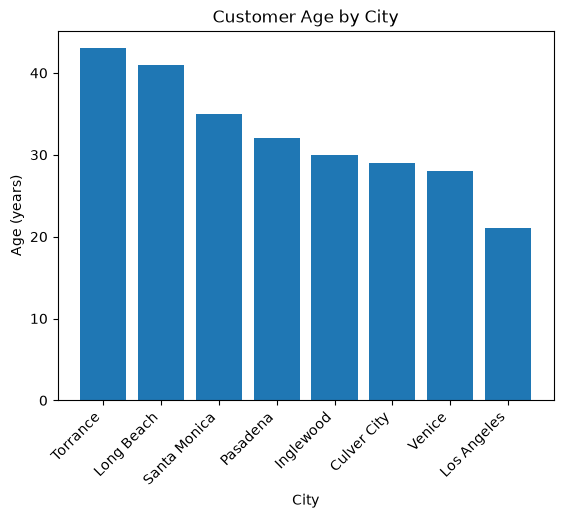

In [6]:
import matplotlib.pyplot as plt
query = """
SELECT city, age
FROM customers
ORDER BY age DESC
"""

df = pd.read_sql_query(query, con)

plt.bar(df["city"], df["age"])

plt.title("Customer Age by City")
plt.xlabel("City")
plt.ylabel("Age (years)")
plt.xticks(rotation=45, ha="right")
plt.show()

Repo Address: https://github.com/KyeSPu/cs82a-portfolio